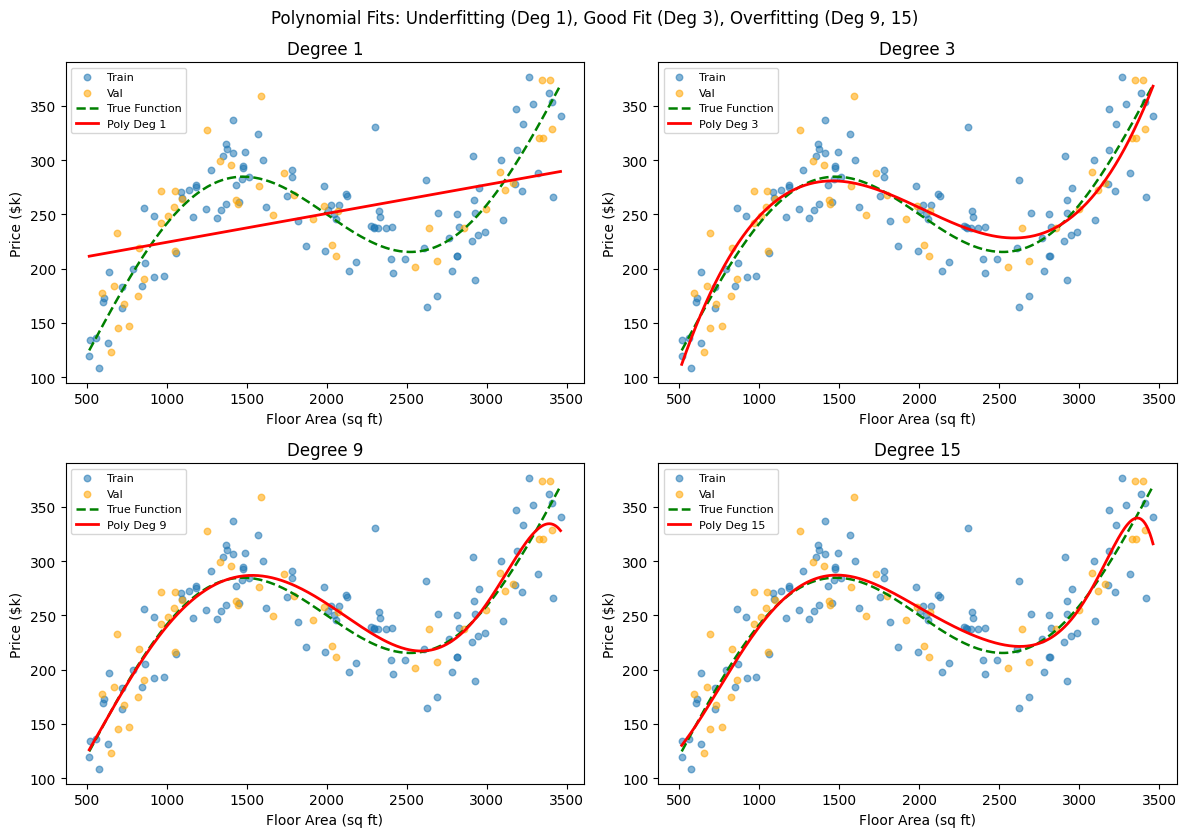

Degree  1 -> Bias²:  1335.27 | Variance:    34.67 | Bias²+Var:  1369.94
Degree  3 -> Bias²:    47.60 | Variance:    35.79 | Bias²+Var:    83.39
Degree  9 -> Bias²:    12.26 | Variance:    51.75 | Bias²+Var:    64.01
Degree 15 -> Bias²:    25.16 | Variance:    57.85 | Bias²+Var:    83.01


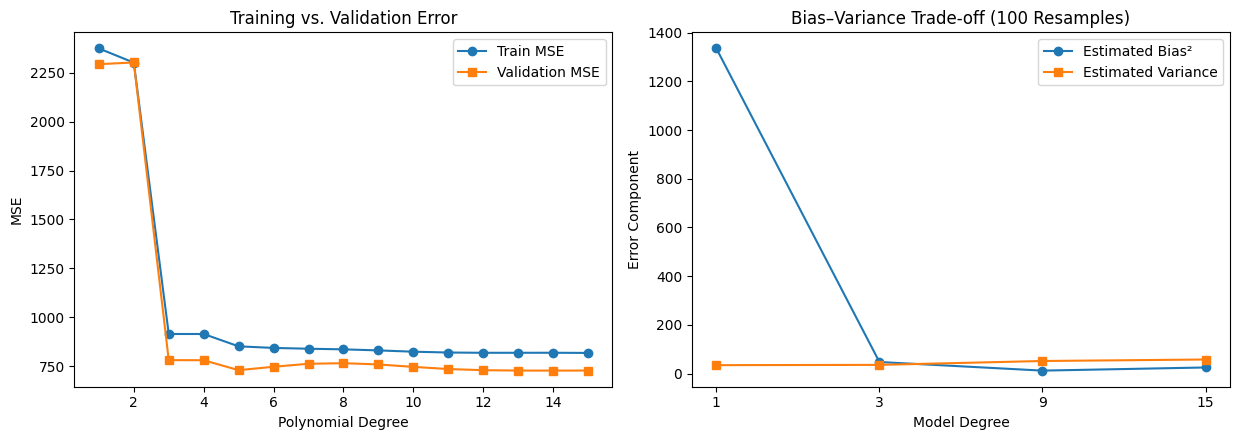


Selected best degree by lowest validation MSE: Degree 14 (captures non-linear curve without high-degree oscillation).


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

np.random.seed(42)

# 1. Generate 150 noisy house area (sq ft) vs price ($k) samples
n_samples = 150
area = np.sort(np.random.uniform(500, 3500, size=n_samples))
x_norm = (area - 500) / 3000.0

def true_price_fn(x):
    return 120 + 260 * x + 90 * np.sin(2 * np.pi * x)

y_true = true_price_fn(x_norm)
price = y_true + np.random.normal(0, 28, size=n_samples)

X = area.reshape(-1, 1)
X_train, X_val, y_train, y_val = train_test_split(X, price, test_size=0.3, random_state=42)

degrees = [1, 3, 9, 15]
x_grid = np.linspace(area.min(), area.max(), 300).reshape(-1, 1)
xg_norm = (x_grid[:, 0] - 500) / 3000.0

# 2. Fit polynomial models (degrees 1, 3, 9, 15) and plot curves
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
axes = axes.ravel()

for ax, deg in zip(axes, degrees):
    model = make_pipeline(PolynomialFeatures(degree=deg), StandardScaler(), Ridge(alpha=1e-6))
    model.fit(X_train, y_train)
    y_pred_grid = model.predict(x_grid)

    ax.scatter(X_train, y_train, alpha=0.55, s=22, label="Train")
    ax.scatter(X_val, y_val, alpha=0.55, s=22, color="orange", label="Val")
    ax.plot(x_grid, true_price_fn(xg_norm), "g--", lw=1.8, label="True Function")
    ax.plot(x_grid, y_pred_grid, "r-", lw=2, label=f"Poly Deg {deg}")
    ax.set_title(f"Degree {deg}")
    ax.set_xlabel("Floor Area (sq ft)")
    ax.set_ylabel("Price ($k)")
    ax.legend(fontsize=8)

plt.suptitle("Polynomial Fits: Underfitting (Deg 1), Good Fit (Deg 3), Overfitting (Deg 9, 15)", fontsize=12)
plt.tight_layout()
plt.savefig("exp05_poly_fits.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Train vs Validation error across degrees 1..15
all_degs = list(range(1, 16))
train_mse, val_mse = [], []
for d in all_degs:
    m = make_pipeline(PolynomialFeatures(degree=d), StandardScaler(), Ridge(alpha=1e-6))
    m.fit(X_train, y_train)
    train_mse.append(mean_squared_error(y_train, m.predict(X_train)))
    val_mse.append(mean_squared_error(y_val, m.predict(X_val)))

# 4. Bias^2 and Variance via repeated resampling (100 bootstrap/resample trials)
n_trials = 100
test_x = np.linspace(600, 3400, 100).reshape(-1, 1)
test_y_true = true_price_fn((test_x[:, 0] - 500) / 3000.0)

bias2_list, var_list = [], []
for d in [1, 3, 9, 15]:
    preds = np.zeros((n_trials, len(test_x)))
    for t in range(n_trials):
        idx = np.random.choice(len(X), size=int(0.7 * len(X)), replace=True)
        m = make_pipeline(PolynomialFeatures(degree=d), StandardScaler(), Ridge(alpha=1e-6))
        m.fit(X[idx], price[idx])
        preds[t] = m.predict(test_x)
    mean_pred = preds.mean(axis=0)
    bias2 = np.mean((mean_pred - test_y_true) ** 2)
    variance = np.mean(np.var(preds, axis=0))
    bias2_list.append(bias2)
    var_list.append(variance)
    print(f"Degree {d:2d} -> Bias²: {bias2:8.2f} | Variance: {variance:8.2f} | Bias²+Var: {bias2+variance:8.2f}")

# Plot Train/Val error & Bias^2 / Variance decomposition
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))

axes[0].plot(all_degs, train_mse, "o-", label="Train MSE")
axes[0].plot(all_degs, val_mse, "s-", label="Validation MSE")
axes[0].set_xlabel("Polynomial Degree")
axes[0].set_ylabel("MSE")
axes[0].set_title("Training vs. Validation Error")
axes[0].legend()

deg_labels = [str(d) for d in [1, 3, 9, 15]]
axes[1].plot(deg_labels, bias2_list, "o-", label="Estimated Bias²")
axes[1].plot(deg_labels, var_list, "s-", label="Estimated Variance")
axes[1].set_xlabel("Model Degree")
axes[1].set_ylabel("Error Component")
axes[1].set_title("Bias–Variance Trade-off (100 Resamples)")
axes[1].legend()

plt.tight_layout()
plt.savefig("exp05_bias_variance.png", dpi=150, bbox_inches="tight")
plt.show()

best_deg = all_degs[int(np.argmin(val_mse))]
print(f"\nSelected best degree by lowest validation MSE: Degree {best_deg} (captures non-linear curve without high-degree oscillation).")